# Single rod @ 12 o'clock - 1e7 / 76 / 2.5

In [1]:
import sys
sys.path.insert(0, "../")

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as colors
from matplotlib import ticker
from math import pi
from decimal import Decimal
from mosh_src.plotting_functions import *

In [3]:
# Set parameters for all plots in notebook
file = "/Users/seanmullane/Desktop/Research_2023/August_outputs/Results_08_04/1rod_12oclock_1e7_76bins_2.5cmHL.csv"
z_slice = 25
norm_point = (0.0, 0.3)
bins = 76
dose_grid_half = 2.5
lattice = dose_grid_half*2/bins
source_transZ = -0.5
source_plane = cm_to_voxel(np.array(source_transZ), bins, dose_grid_half*2/bins)
applicator_rad = 0.3

source_rad = [0.03, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
rngX = (-1.25, 1.25)
rngY = (-1.25, 1.25)

### No zeroing - source dominates

In [4]:
# Scale energy to norm_point
X0, Y0, energy0, std_dev0 = contour_energy(file, (bins, bins), dose_grid_half, source_plane, 2, rngX, rngY, source_rad=source_rad, 
                                           scale=True, norm_point=norm_point, zero_source=False, std_dev=False)

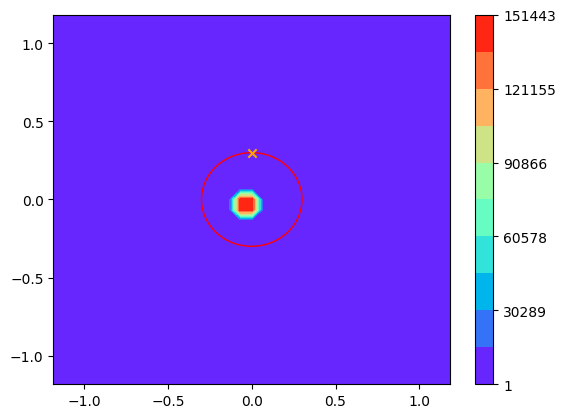

In [5]:
# Linear norm
fig0, ax0 = plt.subplots()
contour = ax0.contourf(X0, Y0, energy0, locator=ticker.LinearLocator(), norm="linear", cmap="rainbow")
cbar = fig0.colorbar(contour)
circle = plt.Circle((0,0), radius=applicator_rad, edgecolor="red", fill=False)
ax0.add_patch(circle)
ax0.scatter(norm_point[0], norm_point[1], color="orange", marker="x")

### Progressive zeroing

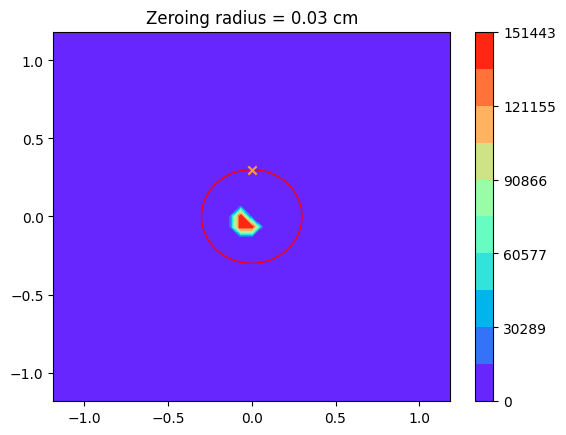

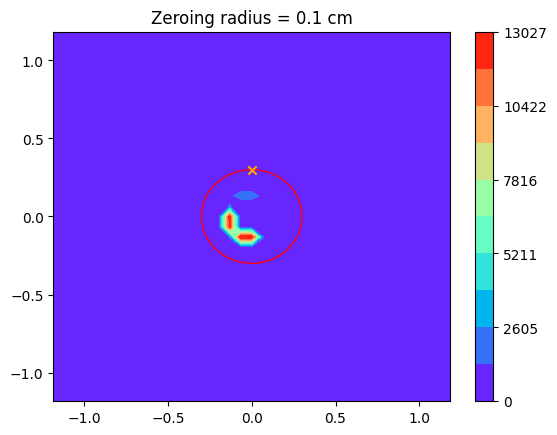

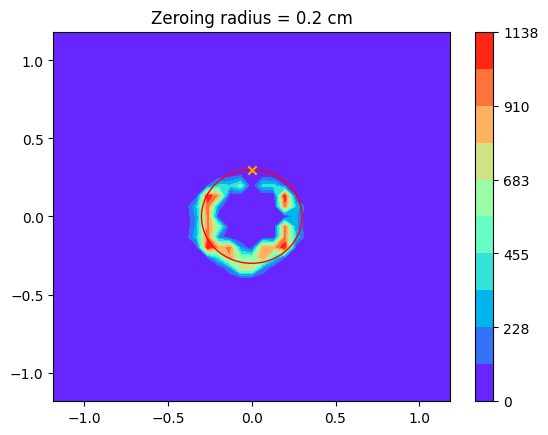

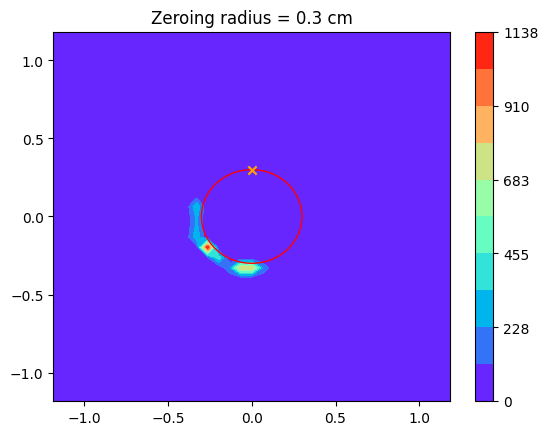

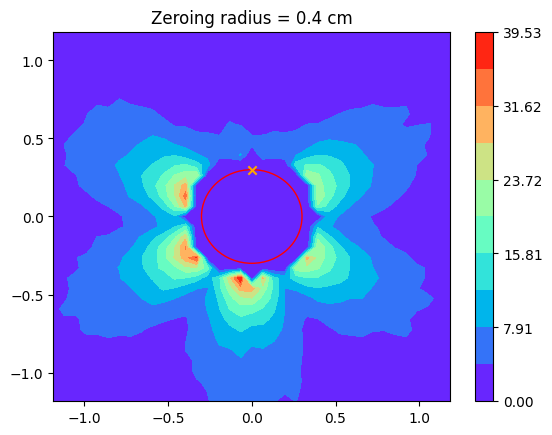

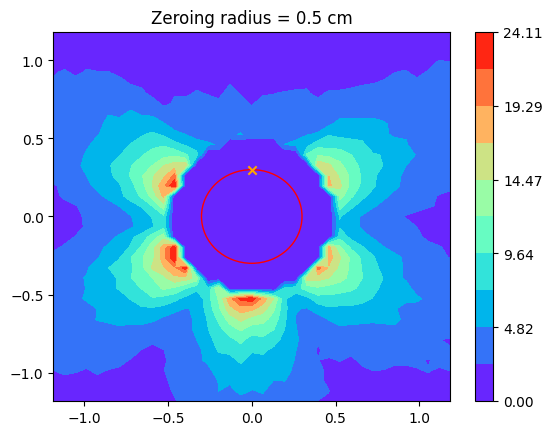

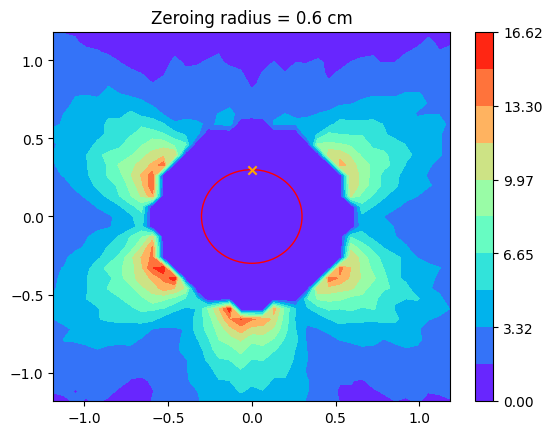

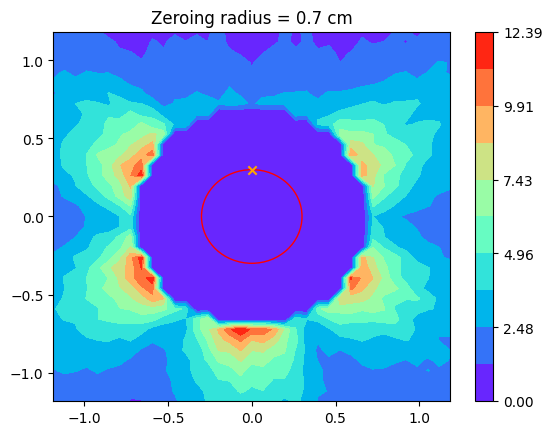

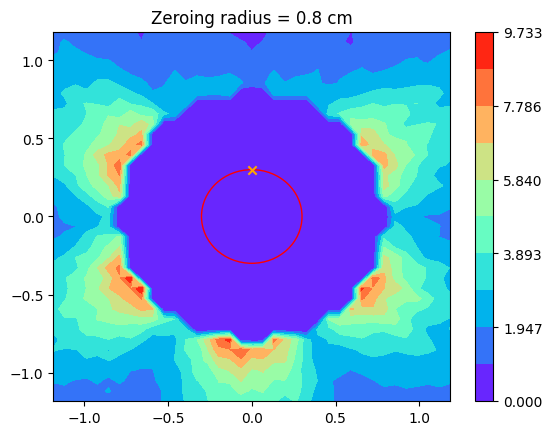

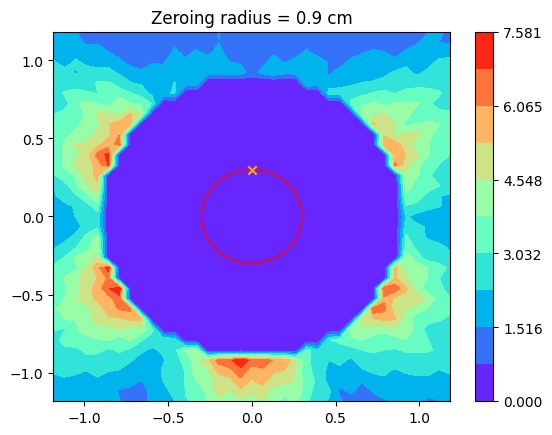

In [6]:
for rad in source_rad:
    X, Y, energy, std_dev = contour_energy(file, (bins, bins), dose_grid_half, source_plane, 2, rngX, rngY, source_rad=rad, 
                                               scale=True, norm_point=norm_point, zero_source=True, std_dev=False)

    fig, ax = plt.subplots()
    contour = ax.contourf(X, Y, energy, locator=ticker.LinearLocator(), norm="linear", cmap="rainbow")
    cbar = fig0.colorbar(contour)
    circle = plt.Circle((0,0), radius=applicator_rad, edgecolor="red", fill=False)
    ax.add_patch(circle)
    ax.scatter(norm_point[0], norm_point[1], color="orange", marker="x")
    ax.set_title("Zeroing radius = " + str(rad) + " cm")

### Testing the normalization point

In [7]:
# Plot focuses on normalization point (0.0, 0.3)
rngX_norm = (-0.4, 0.4)
rngY_norm = (0.15, 1.0)

# To see 100% dose @ norm_point, set rad_norm < 0.3 cm
# To see detailed dose distribution outside applicator, set rad_norm > 0.3 cm
rad_norm = 0.35

Xn, Yn, energyn, std_devn = contour_energy(file, (bins, bins), dose_grid_half, source_plane, 2, rngX_norm, rngY_norm, source_rad=rad_norm, 
                                       scale=True, norm_point=norm_point, zero_source=True, std_dev=False)

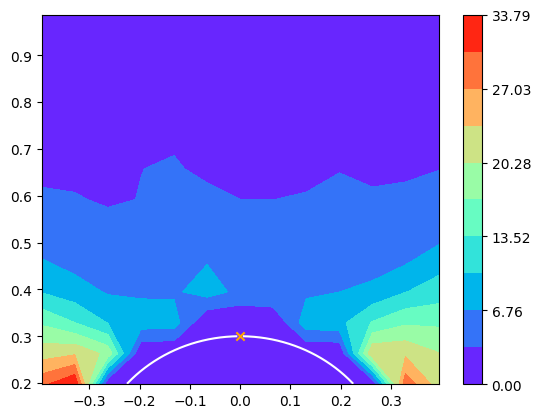

In [8]:
fig1, ax1 = plt.subplots()
contour = ax1.contourf(Xn, Yn, energyn, locator=ticker.LinearLocator(), norm="linear", cmap="rainbow")
cbar = fig1.colorbar(contour)
ax1.scatter(norm_point[0], norm_point[1], color="orange", marker="x")

# Draw applicator edge on plot - note reversal of X, Y compared to other contour zeroing plots
# Right quadrant
x1 = np.arange(rngY_norm[0] + 0.05, applicator_rad, 0.0001)
y1 = np.sqrt(applicator_rad**2 - x1**2)
ax1.plot(y1, x1, color="white")
# Left quadrant
ax1.plot(-y1, x1, color="white")

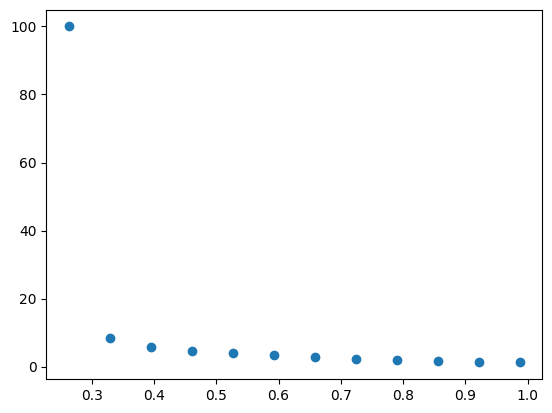

In [9]:
# 1D plot along x-axis, for comparison to contour plot
linear_energy, __ = energy_along_theta(file, pi/2, (bins, bins), dose_grid_half, source_plane, scale=True, norm_point=norm_point)
x, y1, __, __, __ = plotter_1D(linear_energy, plot_rng=(0.25, 1.0)) 

fig2, ax2 = plt.subplots()
ax2.scatter(x, y1)
# Confirms that dose @ (0.0, 0.3) = 100% of prescription dose, as expected